# Assignment 2: Repository setup and the machine learning vocabulary

This assignment has two pieces. **Part 1** sets up the private GitHub repository you will
submit every assignment to. **Part 2** applies the Week 1 machine learning vocabulary to the
[Mauna Loa CO$_2$ record](https://gml.noaa.gov/ccgg/trends/): one short experiment and four
written questions.

The data preprocessing exercises on tropical cyclone records that were originally here are now the
first half of Assignment 3, since we did not finish that material in class.

Answer each numbered question in the empty cell below it.


## Part 1: Create your assignments repository

You will submit every assignment in this course by pushing to a private GitHub repository.
Set it up now.

1. Create a directory called `ml4climate2026` on your machine.
2. Add a `README.md` containing your name.
3. Initialize a git repository, and make your first commit.
4. Create a private repository on GitHub called `ml4climate2026`. Use exactly that name.
   Do not vary the spelling, capitalization, or punctuation.
5. Push your local repository to GitHub.
6. On GitHub, go to **Settings -> Collaborators** and add `dmw2166`.
7. Add this completed notebook to the repository, commit, and push.

Push new commits to this repository whenever you are ready to hand in an assignment, and submit the link to CourseWorks for gradebook purposes.

1) Paste the output of `git log --oneline` below, showing your commit history.

```
deborah@Deborahs-MacBook-Air ml4climate2026 % git log --oneline
9506bd5 (HEAD -> main, origin/main) Adding Assignment 2 to repo
7ca7731 Push local repo to github
```

## Part 2: Intro to ML

The Week 1 lecture notes lay out the vocabulary: the three learning paradigms, the
eight-step workflow, and the strengths and weaknesses of data-driven methods. The questions
in this part ask you to apply those ideas to the
[Mauna Loa CO$_2$ record](https://gml.noaa.gov/ccgg/trends/), the longest continuous direct
measurement of atmospheric carbon dioxide anywhere in the world.

The cell below loads the record for you. If you did the optional coding review in
Assignment 1 you have seen it before; if not, run it and look at the columns. `average` is the
monthly mean concentration in ppm and `decimal_date` is the time of each value as a decimal
year, which is the natural x variable for fitting.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The Mauna Loa CO2 record, straight from NOAA. The file has about 40 lines of
# header comments before the data begins, which comment="#" skips.
url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
co2 = pd.read_csv(url, comment="#")
co2 = co2.rename(columns={"decimal date": "decimal_date"})

# Build a proper datetime column (measurements are monthly means, dated mid-month).
co2["date"] = pd.to_datetime(dict(year=co2["year"], month=co2["month"], day=15))

# NOAA codes missing monthly means as -99.99.
co2 = co2[co2["average"] > 0].reset_index(drop=True)

co2.head()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc,date
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99,1958-03-15
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99,1958-04-15
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99,1958-05-15
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99,1958-06-15
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99,1958-07-15


2) Before answering anything conceptual, run one experiment.

Fit a straight line to the record using **only the data up to the end of 1999**
(`numpy.polyfit` on `decimal_date` against `average`, degree 1). Then use that line to
predict CO$_2$ for 2000 onwards. Plot the observations for the whole record together with
the extrapolated line, and report the prediction error in ppm for the most recent year in
the dataset.

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc,date,predicted,prediction_error
814,2026,1,2026.0417,428.62,428.32,25,0.69,0.27,2026-01-15,400.447245,-28.172755
815,2026,2,2026.1250,429.35,428.40,17,0.74,0.34,2026-02-15,400.557473,-28.792527
816,2026,3,2026.2083,430.15,428.68,26,0.87,0.33,2026-03-15,400.667702,-29.482298
817,2026,4,2026.2917,431.12,428.61,23,1.16,0.46,2026-04-15,400.778063,-30.341937
818,2026,5,2026.3750,432.34,429.06,19,0.64,0.28,2026-05-15,400.888291,-31.451709
819,2026,6,2026.4583,431.43,428.99,19,0.27,0.12,2026-06-15,400.998520,-30.431480
820,2026,7,2026.5417,429.13,428.78,21,0.61,0.26,2026-07-15,401.108880,-28.021120
821,2026,8,2026.6250,427.55,429.51,17,0.36,0.17,2026-08-15,401.219109,-26.330891


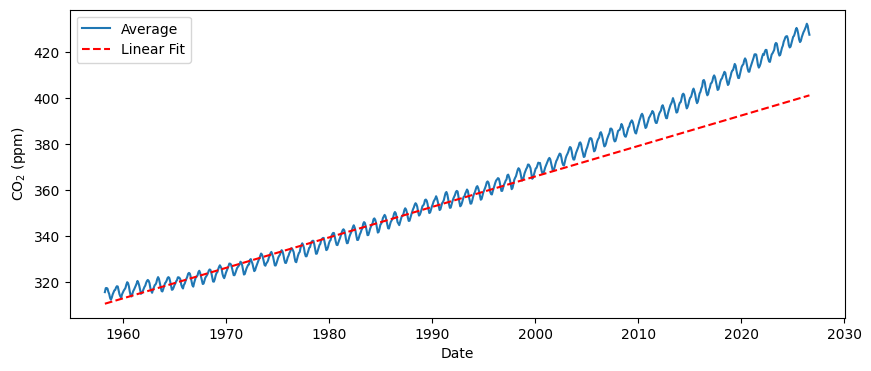

In [14]:
data_pre_2000 = co2[co2['year'] <= 1999]
slope, intercept = np.polyfit(data_pre_2000['decimal_date'], data_pre_2000['average'], 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(co2["date"], co2["average"], label='Average')
ax.plot(co2["date"], slope*co2['decimal_date'] + intercept, 'r--', label='Linear Fit')
ax.set_xlabel('Date')
ax.set_ylabel('CO$_2$ (ppm)')
ax.legend()

co2['year'].unique()
last_year = co2[co2['year'] == 2026].copy()
last_year['predicted'] = last_year['decimal_date']*slope+intercept
last_year['prediction_error'] = last_year['predicted'] - last_year['average']
last_year

3) You have now fit a model that learned two parameters from data (slope and intercept) and made predictions
without anyone programming the relationship explicitly. By the definition given in the
lecture notes, is `numpy.polyfit` a machine learning algorithm? Justify your answer.

Definitionally, polyfit is a machine learning algorithm because it uses the data to learn what the slope and intercept are. I did not explicitly program slope and intercept as fixed variables but instead extracted those values from the data.

4) The notes divide machine learning into supervised, unsupervised, and reinforcement
learning. Consider two operations on this record:

- **(a)** the straight-line fit of concentration against date (question 2)
- **(b)** extracting the mean seasonal cycle by grouping the record by calendar month and
  averaging the departure of each month from the deseasonalized trend (the optional coding
  review in Assignment 1 does this; you do not need to have done it to answer)

Which paradigm, if any, does each belong to? 

a) Supervised learning - The straight line fit is a form of regression. It extracts intercept and slope from a set of data and uses that to predict data

b) Unsupervised learning - Extracting the mean seasonal cycle is feature elicitation. It is parsing the data to figure out a certain feature that is present in the data.

5) Frame a genuine **supervised learning** problem using this dataset. You are not being asked to implement it. Your answer must
specify, concretely:

- the input features and the label 
- how you would split the data into training and test sets
- what loss function you would minimize
- what result would make you conclude the model had learned something real, as opposed to
  something you already knew


Supervised learning problem: Using the input data to predict future CO2 levels

Input features: Decimal date as the input feature and average for the label

Data split: first 70% of data to be the training set, next 15% to be the validation set and the last 15% to be the test set.

Loss function to minimize: the mean squared error of predict average to actual average CO2 levels for each month

If the model was able to accurately predict CO2 levels and was able to account for the curve in the graph rather than just a linear fit.

6) The notes state that machine learning models "typically do a poor job of extrapolating
to unseen data regimes." Your experiment in question 2 is a small demonstration of exactly
that.

Suppose you needed a projection of atmospheric CO$_2$ for the year 2100. Would a flexible
machine learning model (a neural network, say) trained on this same record do better or
worse than your straight line? Explain your reasoning, and then explain what a
physics-based carbon cycle model has access to that neither of them does.

2100 is very far into the future. There is about 70 years of data and 2100 is 70 years into the future. Based on current data, a model could infer that a linear or linear esque model might be appropriate if it assumes that the last few years are anomalous. A flexible machine learning model might do better but it might not. 70 years into the future is so far that it is hard to predict if it will remain linear, plateau, spike up exponentially or something else entirely.

A physics based carbon cycle model has access to the underlying mechanics of the carbon cycle system that describes what causes carbon levels to increase and decrease. It can factor in causes like fossil fuel emissions and other contributors to more accurately predict into the future.